# Time-varying energy spectra for all Concordiasi and Strateole-2 data

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.cm
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
from mpl_toolkits.basemap import Basemap
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
# Replace Basemap with Cartopy:
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

### Constants

In [2]:
# Physical constants
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth

# Time series properties
dt = 0.5 # (minutes) the time step of the interpolated data

# Thresholds for limiting the size of spectra
PERIOD_MIN = 5 # (minutes) the minimum period to be included in the spectrum
PERIOD_MAX = 2*24*60 # (minutes) the maximum period to be included in the spectrum
GW_PERIOD_MIN = 10 # (minutes) the minimum period for frequency-integrated momentum fluxes
GW_PERIOD_MAX = 1*24*60 # (minutes) the maximum GW period

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

# Instrumental uncertainties
GPS_uncertainty = 1.5 # (m) from Corcos et al. (2021), Podglajen et al. (2020)
u_uncertainty = np.sqrt(2)*GPS_uncertainty/30 # (m/s) the typical timestep in the raw data is 30s
v_uncertainty = np.sqrt(2)*GPS_uncertainty/30 # (m/s) the typical timestep in the raw data is 30s

### Load in the data

In [3]:
#flights = pd.read_feather('../../processing/Concordiasi_with_ERA5_5_interpolated.feather')
flights = pd.read_feather('../../processing/Strateole2_with_ERA5_4_interpolated.feather')
flights

,flight_id,time,latitude,longitude,altitude,pressure,wind_u,wind_v,T_ERA5,N2_ERA5,superpressure,segment_id
0,C0_01_STR1,2019-11-12 22:25:30,-4.836130,55.593712,20297.688624,53.897755,0.392599,-8.409890,203.430391,0.000691,8.270000,0
1,C0_01_STR1,2019-11-12 22:26:00,-4.838373,55.593802,20297.000000,53.897010,0.275275,-8.363094,203.430718,0.000691,8.209750,0
2,C0_01_STR1,2019-11-12 22:26:30,-4.840622,55.593861,20303.627514,53.822979,0.208103,-8.508461,203.463195,0.000691,8.200000,0
3,C0_01_STR1,2019-11-12 22:27:00,-4.842951,55.593915,20305.935137,53.775627,0.192059,-8.919195,203.483963,0.000691,8.690159,0
4,C0_01_STR1,2019-11-12 22:27:30,-4.845411,55.593966,20299.019538,53.819265,0.137937,-8.885177,203.464825,0.000691,8.770000,0
...,...,...,...,...,...,...,...,...,...,...,...,...
3685569,C1_17_TTL3,2021-12-16 12:31:00,-2.212779,125.869692,18639.777133,71.023424,-3.031736,3.200112,192.007890,0.000810,10.779291,74
3685570,C1_17_TTL3,2021-12-16 12:31:30,-2.211940,125.868848,18621.344802,71.260980,-3.256378,2.967137,191.965922,0.000809,10.484118,74
3685571,C1_17_TTL3,2021-12-16 12:32:00,-2.211183,125.867939,18599.995817,71.532102,-3.427718,2.669256,191.918319,0.000809,10.158603,74
3685572,C1_17_TTL3,2021-12-16 12:32:30,-2.210504,125.867000,18591.404062,71.649013,-3.458552,2.449228,191.897890,0.000808,9.918572,74


### Wavelet analysis function

In [4]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    #X_recon: float;
    wave: float;
    #wave_power: float;
    #total_power: float;
    #global_power: float;
    global_power_rescaling: float;
    #total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    #fftfreq: float;
    #fft: float;
    #fft_power: float;
    #fft_total_power: float;
    #fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    ## Reconstruct the input time series
    #psi_0_0 = np.pi**-0.25 # (Table 2)
    #X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    # Calculate dimensional quantities
    N = N - 2*N_pad # N now matches the input time series length again
    ## The scaling is chosen so that the values are correct after the zero padding is removed
    #var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    #wave_power = (var/var_ratio)*np.abs(wave)**2
    #global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    #total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    #total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    #global_total_power = (1/N)*np.sum(total_power)
    #X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    ## FFT analysis
    #ind_switchfreq_fft = 1 + int(np.floor(N/2))
    #fft = np.fft.fft(X/std)
    #fftfreq = np.fft.fftfreq(N,dt)
    #fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    #fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    #fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    #fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    #fft_total_power = (1/N)*np.sum(fft_power)
    #fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       #X_recon,
                       wave,
                       #wave_power,
                       #total_power,
                       #global_power,
                       global_power_rescaling,
                       #total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi)
                       #fftfreq,
                       #fft,
                       #fft_power,
                       #fft_total_power,
                       #fft_power_rescaling)

### Analyze the segment

In [5]:
def analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,PERIOD_MAX,GW_PERIOD_MAX):

    # Convert time to a numpy array with units of minutes
    t = np.array((segment.time - segment.time.iloc[0])/pd.Timedelta('1 minutes'))
    N = np.size(t)
    # Make other variables arrays
    u = np.array(segment.wind_u)
    v = np.array(segment.wind_v)
    pt = 100*np.array(segment.pressure) # the Strateole-2, Concordiasi data have pressure units of hPa; convert to Pa
    altitude = np.array(segment.altitude)
    balloon_lat = np.array(segment.latitude)
    T_env = np.array(segment.T_ERA5)
    Nref = np.sqrt(np.array(segment.N2_ERA5))
    
    # Calculate segment mean environmental properties
    rho_bar = np.nanmean(pt/(R*T_env))
    T_env = np.nanmean(T_env)
    Nref = np.nanmean(Nref)
    
    # Calculate the environmental lapse rate
    dTdz_env = (T_env/g)*(Nref**2) - (g/cp) # VH14 Eq. 6
    
    # Calculate the segment mean density scale height
    H = T_env/(dTdz_env + g/R)
    
    # Calculate the segment mean Coriolis parameter
    f = np.mean(2*Omega*np.sin(np.pi*balloon_lat/180)) 
    
    # Calculate Z_EDS
    Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
    
    # Create time series of anomalies by detrending
    u = scipy.signal.detrend(u)
    v = scipy.signal.detrend(v)
    pt = scipy.signal.detrend(pt)
    delta_b = scipy.signal.detrend(altitude)
    
    # Calculate delta_theta and w, using Z_EDS
    delta_theta = delta_b/Z_EDS
    w = np.zeros(shape=(N)) # choose not to worry about the first and last value of w
    w[1:-1] = 0.5*(delta_theta[2:] - delta_theta[:-2])/(60*dt)
    
    # Run the wavelet analyses on the segment
    segment_spectra_output = segment_spectra(t,w,u,v,delta_theta,balloon_lat,
                                             omega0,dt,dj,
                                             Nref,rho_bar,Omega,Z_EDS,H,PERIOD_MAX,GW_PERIOD_MAX)
    
    return segment_spectra_output

### Calculate energy spectra time series

In [6]:
def segment_spectra(t,w,u,v,delta_theta,balloon_lat,
                    omega0,dt,dj,
                    Nref,rho_bar,Omega,Z_EDS,H,PERIOD_MAX,GW_PERIOD_MAX):

    N = np.size(t)

    # Time series' variance
    std_w = np.std(w)
    std_u = np.std(u)
    std_v = np.std(v)
    std_delta_theta = np.std(delta_theta)
    var_w = std_w**2
    var_u = std_u**2
    var_v = std_v**2
    var_delta_theta = std_delta_theta**2
    
    # Run the wavelet analysis
    w_output = run_Morlet_CWT(w,dt,omega0,dj)
    u_output = run_Morlet_CWT(u,dt,omega0,dj)
    v_output = run_Morlet_CWT(v,dt,omega0,dj)
    delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj)
    # Pull out a couple common variables to make some calculations easier
    period = u_output.period; frequency = u_output.frequency; scale = u_output.s
    N_pad = u_output.N_pad; coi = u_output.coi
    nscales = np.size(scale)
    var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    
    
    
    ## ENERGY WAVELET
    # Calculate the EKE from the zero-padded wavelet output
    wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                                var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
    wave_Ekv = (0.5/var_ratio)*(var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2)
    # Calculate the EPE from the zero-padded wavelet output
    wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
              np.abs(delta_theta_output.wave)**2 # Eq. 2, Podglajen et al 2016
    # Calculate total energy
    wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep
    del wave_Ekh, wave_Ekv, wave_Ep
    
    
    
    ## PROCESS THE WAVELET
    # Remove zero padding
    wave_Etotal = wave_Etotal[:,N_pad:N+N_pad]
    # Identify wavelet coefficients inside the COI
    temp1 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2 = np.tile(coi,(nscales,1))
    temp1[temp1 > temp2] = np.nan
    del temp2
    temp1 = temp1/temp1
    # Identify wavelet coefficients with frequencies lower than f or the minimum GW frequency
    temp2 = 2*60*Omega*np.sin(np.pi*np.abs(balloon_lat)/180) # Coriolis frequency in rad/min
    temp2 = 2*np.pi/temp2
    temp2 = np.minimum(temp2,GW_PERIOD_MAX)
    temp2 = np.tile(temp2,(nscales,1))
    temp3 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2[temp2 < temp3] = np.nan
    del temp3
    temp2 = temp2/temp2
    temp1 = temp1*temp2
    del temp2
    # Delete the offending wavelet coefficients
    wave_Etotal = wave_Etotal*temp1
    del temp1
    # Identify the periods less than or equal to PERIOD_MAX
    nscales_new = np.arange(nscales)
    nscales_new = nscales_new[period <= PERIOD_MAX]
    nscales_new = nscales_new.size
    period = period[:nscales_new]
    wave_Etotal = wave_Etotal[:nscales_new,:]
    # Identify the periods greater or equal to PERIOD_MIN
    ind = np.arange(nscales_new)
    ind = ind[period >= PERIOD_MIN]
    ind = ind[0]
    period = period[ind:]
    wave_Etotal = wave_Etotal[ind:,:]
    # Convert to a DataFrame for output
    column_names = np.round(period,2).astype(np.str)
    segment_spectra_output = pd.DataFrame(wave_Etotal.swapaxes(0,1), columns=column_names)
    
    
    
    return segment_spectra_output

In [7]:
# Calculate momentum flux time series for each data segment

segment_ids = flights.segment_id.unique()
n_segments = flights.segment_id.nunique()

segments_analyzed = pd.DataFrame(columns = flights.columns)

for i in np.arange(n_segments):
    segment = flights[flights.segment_id == segment_ids[i]]
    print('Analyzing segment', i+1, 'out of', n_segments, 'segments')
    print('Segment length:', segment.time.max() - segment.time.min())
    print('Current time:', datetime.datetime.now())
    temp = analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,PERIOD_MAX,GW_PERIOD_MAX)
    temp.index = segment.index
    segment = pd.concat([segment, temp], axis=1)
    segments_analyzed = segments_analyzed.append(segment, ignore_index=True)
    print('')

#segments_analyzed.to_feather('Concordiasi_omega0_8_EtotalWavelet_f_cutoff.feather') 
segments_analyzed.to_feather('Strateole2_omega0_8_EtotalWavelet_f_cutoff.feather') 

Analyzing segment 1 out of 57 segments
Segment length: 23 days 10:04:00
Current time: 2025-07-30 17:21:04.391442

Analyzing segment 2 out of 57 segments
Segment length: 8 days 20:14:00
Current time: 2025-07-30 17:21:26.602265

Analyzing segment 3 out of 57 segments
Segment length: 7 days 20:14:00
Current time: 2025-07-30 17:21:33.012120

Analyzing segment 4 out of 57 segments
Segment length: 14 days 14:29:00
Current time: 2025-07-30 17:21:38.444641

Analyzing segment 5 out of 57 segments
Segment length: 2 days 02:29:00
Current time: 2025-07-30 17:21:49.298090

Analyzing segment 6 out of 57 segments
Segment length: 43 days 04:16:30
Current time: 2025-07-30 17:21:50.533952

Analyzing segment 7 out of 57 segments
Segment length: 27 days 09:32:30
Current time: 2025-07-30 17:22:47.712022

Analyzing segment 8 out of 57 segments
Segment length: 75 days 10:02:00
Current time: 2025-07-30 17:23:13.381496

Analyzing segment 9 out of 57 segments
Segment length: 3 days 19:52:00
Current time: 2025-0

In [7]:
# Load in the analyzed data
#flights = pd.read_feather('Concordiasi_omega0_8_EtotalWavelet_f_cutoff.feather')
flights = pd.read_feather('Strateole2_omega0_8_EtotalWavelet_f_cutoff.feather')
#flights = pd.read_feather('Concordiasi_omega0_8_EtotalWavelet.feather')
#flights = pd.read_feather('Strateole2_omega0_8_EtotalWavelet.feather')

print('Dataset mean latitude:', flights.latitude.mean())

# Retrieve the periods
period_column_start = 12
period_column_stop = 231
period_names = np.array(flights.columns[period_column_start:period_column_stop+1])
period = np.array(flights.columns[period_column_start:period_column_stop+1]).astype('float')
frequency = 1/period
n_periods = period.size
n_data = flights.shape[0]

# Save segment-mean length and factors for the GW vertical velocity and potential energy uncertainties
# The vertical velocity factor is calculated so that the power of w_uncertainty is weighted by segment length
segment_ids = flights.segment_id.unique()
n_segments = flights.segment_id.nunique()
segments_N = np.nan*np.ones(n_segments)
segments_w_factor = np.nan*np.ones(n_segments)
segments_Ep_factor = np.nan*np.ones(n_segments)
segments_Nref = np.nan*np.ones(n_segments)
for i in np.arange(n_segments):
    segment = flights[flights.segment_id == segment_ids[i]]
    segments_N[i] = segment.shape[0]
    # Calculations are as in the analyze_segment function
    pt = 100*np.array(segment.pressure) # the Strateole-2, Concordiasi data have pressure units of hPa; convert to Pa
    T_env = np.array(segment.T_ERA5)
    Nref = np.sqrt(np.array(segment.N2_ERA5))
    T_env = np.nanmean(T_env)
    Nref = np.nanmean(Nref)
    dTdz_env = (T_env/g)*(Nref**2) - (g/cp) # VH14 Eq. 6
    Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
    segments_w_factor[i] = (1/Z_EDS)**2
    segments_Ep_factor[i] = (Nref/Z_EDS)**2
    segments_Nref[i] = Nref
temp = segments_w_factor/segments_w_factor # To deal with any segments with NaN ERA5 data
segments_w_factor = np.sqrt(np.nansum(segments_w_factor*segments_N)/np.nansum(temp*segments_N))
temp = segments_Ep_factor/segments_Ep_factor # To deal with any segments with NaN ERA5 data
segments_Ep_factor = np.nansum(segments_Ep_factor*segments_N)/np.nansum(temp*segments_N)

# Make a matrix of all the values
energy = np.nan*np.ones(shape=(n_periods,n_data))
for i in np.arange(n_periods):
    energy[i,:] = np.array(flights[period_names[i]])

# Delete the flight data to save space
del flights # to save space

Dataset mean latitude: -2.7951510043009886


In [8]:
# Calculate the mean energy spectrum and find the upper and lower quantiles
quant_low1 = 0.01
quant_high1 = 0.99
quant_low2 = 0.1
quant_high2 = 0.9

energy_mean = np.nanmean(energy, axis=1)
energy_quant_low1 = np.nanquantile(energy, quant_low1, axis=1)
energy_quant_high1 = np.nanquantile(energy, quant_high1, axis=1)
energy_quant_low2 = np.nanquantile(energy, quant_low2, axis=1)
energy_quant_high2 = np.nanquantile(energy, quant_high2, axis=1)

In [9]:
# The spectrum of instrumental uncertainty
# This is done by scaling a power spectrum with the shape frequency**2 (amplitude
# a linear function of frequency) so that its total power equals the square of
# the instrumental uncertainty.
scaling_factor_velocity = (np.log2(np.exp(1))/dj)/np.sum(frequency**3)
scaling_factor_altitude = (np.log2(np.exp(1))/dj)/np.sum(frequency)
u_uncertainty_power = scaling_factor_velocity*(u_uncertainty*frequency)**2
v_uncertainty_power = scaling_factor_velocity*(v_uncertainty*frequency)**2
w_uncertainty = segments_w_factor*np.sqrt(2)*GPS_uncertainty/30
w_uncertainty_power = scaling_factor_velocity*(w_uncertainty*frequency)**2
delta_b_uncertainty_power = scaling_factor_altitude*np.ones(n_periods)*GPS_uncertainty**2

# Energy of the uncertainty
Ekh_uncertainty = 0.5*(u_uncertainty_power + v_uncertainty_power)
Ekv_uncertainty = 0.5*w_uncertainty_power
Ep_uncertainty = 0.5*segments_Ep_factor*delta_b_uncertainty_power
Etotal_uncertainty = Ekh_uncertainty + Ekv_uncertainty + Ep_uncertainty

# Effective momentum flux spectrum due to the uncertainty
rho_temp = 0.1 # (kg/m**3)
lat_temp = -70 # (degN)
Nref_temp = 0.02 # (rad/s)
f_temp = 2*Omega*np.sin(np.pi*lat_temp/180)
frequency_rad = 2*np.pi*frequency/60
factor = (frequency_rad**2 - f_temp**2)/(Nref_temp**2 - f_temp**2)
factor = factor*(Nref_temp**2 - frequency_rad**2)/(Nref_temp**2 - f_temp**2)
factor = np.sqrt(factor)
Etotal_uncertainty_rescaled = factor*Etotal_uncertainty

# Isolate the GW frequency range and integrate
Etotal_uncertainty_rescaled[period < GW_PERIOD_MIN] = np.nan
max_period = min(GW_PERIOD_MAX, 2*np.pi/(np.abs(f_temp)*60))
Etotal_uncertainty_rescaled[period > max_period] = np.nan
Etotal_uncertainty_rescaled = 1000*rho_temp*dj*np.log(2)*np.nansum(Etotal_uncertainty_rescaled/period)
print('Effective momentum flux due to instrumental uncertainty (mPa):', Etotal_uncertainty_rescaled)

Effective momentum flux due to instrumental uncertainty (mPa): 0.176544153111989


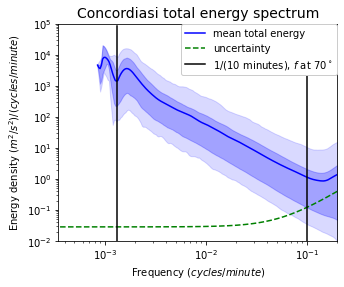

In [6]:
# Plot
temp_f = 2*Omega*np.sin(np.pi*70/180)
temp_f = 60*temp_f/(2*np.pi)

plt.figure(figsize=(5,4))
plt.plot(frequency, energy_mean, 'b')
plt.fill_between(frequency, energy_quant_low1, energy_quant_high1, color='b', alpha=0.15)
plt.fill_between(frequency, energy_quant_low2, energy_quant_high2, color='b', alpha=0.25)
plt.plot(frequency, Etotal_uncertainty, '--g')
plt.plot([1/10, 1/10], [0, 10*np.nanmax(energy_mean)],'k')
plt.plot([temp_f, temp_f], [0, 10*np.nanmax(energy_mean)],'k')
plt.xlim(1/(2*24*60),1/5)
plt.ylim(1E-2,1E5)
plt.xscale('log')
plt.yscale('log')
plt.title('Concordiasi total energy spectrum', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Energy density $(m^{2}/s^{2})/(cycles/minute)$')
plt.legend(['mean total energy','uncertainty','1/(10 minutes), $f$ at 70$^\circ$'],
           loc='upper right', bbox_to_anchor=(1.016, 1.019), framealpha=1);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');

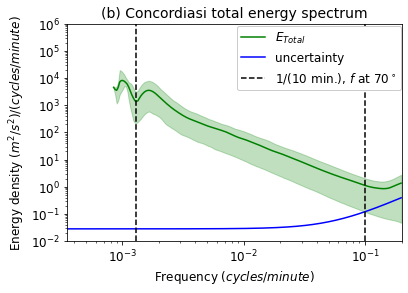

In [12]:
# Plot
temp_f = 2*Omega*np.sin(np.pi*70/180)
temp_f = 60*temp_f/(2*np.pi)

ymin = 1E-2
ymax = 1E6
plt.figure(figsize=(6,4))
plt.plot(frequency, energy_mean, 'g')
plt.fill_between(frequency, energy_quant_low2, energy_quant_high2, color='g', alpha=0.25)
plt.plot(frequency, Etotal_uncertainty, 'b')
plt.plot([1/10, 1/10], [ymin, ymax],'--k')
plt.plot([temp_f, temp_f], [ymin, ymax],'--k')
plt.xlim(1/(2*24*60),1/5)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title('(b) Concordiasi total energy spectrum', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Energy density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$E_{Total}$',
            'uncertainty',
            '1/(10 min.), $f$ at 70$^\circ$'],
           loc='upper right', bbox_to_anchor=(1.016, 1.019), framealpha=1, fontsize=12);
plt.savefig('../plots/temp6b.pdf', format='pdf', bbox_inches='tight');

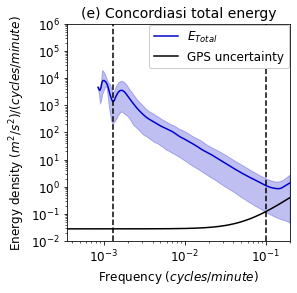

In [6]:
temp_f = 2*Omega*np.sin(np.pi*70/180)
temp_f = 60*temp_f/(2*np.pi)

ymin = 1E-2
ymax = 1E6
plt.figure(figsize=(4,4))
plt.plot(frequency, energy_mean, c=matplotlib.colors.CSS4_COLORS['mediumblue'])
plt.fill_between(frequency, energy_quant_low2, energy_quant_high2,
                 color=matplotlib.colors.CSS4_COLORS['mediumblue'], alpha=0.25)
plt.plot(frequency, Etotal_uncertainty, 'k')
plt.plot([1/10, 1/10], [ymin, ymax],'--k')
plt.plot([temp_f, temp_f], [ymin, ymax],'--k')
plt.xlim(1/(2*24*60),1/5)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title('(e) Concordiasi total energy', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Energy density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$E_{Total}$',
            'GPS uncertainty'],
           loc='upper right', bbox_to_anchor=(1.023, 1.024), framealpha=1, fontsize=12);
plt.savefig('../plots/temp6c.pdf', format='pdf', bbox_inches='tight');

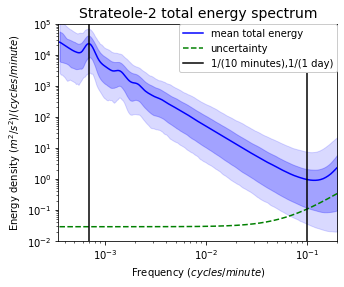

In [13]:
# Plot

plt.figure(figsize=(5,4))
plt.plot(frequency, energy_mean, 'b')
plt.fill_between(frequency, energy_quant_low1, energy_quant_high1, color='b', alpha=0.15)
plt.fill_between(frequency, energy_quant_low2, energy_quant_high2, color='b', alpha=0.25)
plt.plot(frequency, Etotal_uncertainty, '--g')
plt.plot([1/10, 1/10], [0, 10*np.nanmax(energy_mean)],'k')
plt.plot([1/1440, 1/1440], [0, 10*np.nanmax(energy_mean)],'k')
plt.xlim(1/(2*24*60),1/5)
plt.ylim(1E-2,1E5)
plt.xscale('log')
plt.yscale('log')
plt.title('Strateole-2 total energy spectrum', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Energy density $(m^{2}/s^{2})/(cycles/minute)$')
plt.legend(['mean total energy','uncertainty','1/(10 minutes),1/(1 day)'],
           loc='upper right', bbox_to_anchor=(1.016, 1.019), framealpha=1);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');

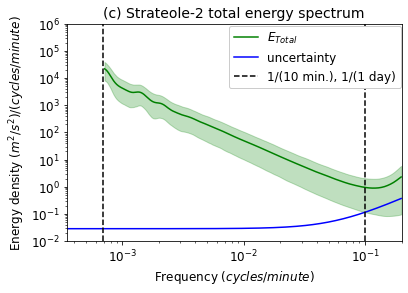

In [6]:
# Plot
ymin = 1E-2
ymax = 1E6
plt.figure(figsize=(6,4))
plt.plot(frequency, energy_mean, 'g')
plt.fill_between(frequency, energy_quant_low2, energy_quant_high2, color='g', alpha=0.25)
plt.plot(frequency, Etotal_uncertainty, 'b')
plt.plot([1/10, 1/10], [ymin, ymax],'--k')
plt.plot([1/1440, 1/1440], [ymin, ymax],'--k')
plt.xlim(1/(2*24*60),1/5)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title('(c) Strateole-2 total energy spectrum', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Energy density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$E_{Total}$',
            'uncertainty',
            '1/(10 min.), 1/(1 day)'],
           loc='upper right', bbox_to_anchor=(1.016, 1.019), framealpha=1, fontsize=12);
plt.savefig('../plots/temp7b.pdf', format='pdf', bbox_inches='tight');

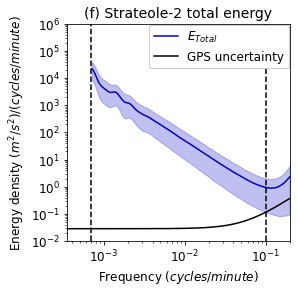

In [10]:
ymin = 1E-2
ymax = 1E6
plt.figure(figsize=(4,4))
plt.plot(frequency, energy_mean, c=matplotlib.colors.CSS4_COLORS['mediumblue'])
plt.fill_between(frequency, energy_quant_low2, energy_quant_high2,
                 color=matplotlib.colors.CSS4_COLORS['mediumblue'], alpha=0.25)
plt.plot(frequency, Etotal_uncertainty, 'k')
plt.plot([1/10, 1/10], [ymin, ymax],'--k')
plt.plot([1/1440, 1/1440], [ymin, ymax],'--k')
plt.xlim(1/(2*24*60),1/5)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title('(f) Strateole-2 total energy', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Energy density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$E_{Total}$',
            'GPS uncertainty'],
           loc='upper right', bbox_to_anchor=(1.023, 1.024), framealpha=1, fontsize=12);
plt.savefig('../plots/temp7c.pdf', format='pdf', bbox_inches='tight');